 ## Practical Assistant Agent

---

## What you will build

A **Practical Assistant Agent** - a real, useful tool AI Agent.

- Talks to **at least 2 real external services** (Notion, GitHub, Gmail, Calendar, Slack — pick any 2+).
- Has **memory** so it can hold a multi-turn conversation.
- **Stops and asks the human** before doing anything destructive or irreversible (sending an email, deleting a file, posting publicly, creating a calendar event).

You can use custom python functions as tools, free APIs or any other API you want to try.

---
## Examples of free APIs you can use (no OAuth, mostly no key)

Pick **one or two** of these. Quick reference:

| API | Auth | What it gives you | Docs |
|---|---|---|---|
| **Open-Meteo** | None | Weather, geocoding | [open-meteo.com](https://open-meteo.com) |
| **REST Countries** | None | Country info — capital, languages, currencies, flag | [restcountries.com](https://restcountries.com) |
| **Wikipedia** | None | Topic summaries (via `langchain_community.tools.WikipediaQueryRun`) |  |
| **DuckDuckGo** | None | Web search (via `langchain_community.tools.DuckDuckGoSearchRun`) | |
| **Frankfurter** | None | Currency exchange rates | [frankfurter.app](https://www.frankfurter.app) |
| **CoinGecko** | None (free tier) | Crypto prices, no key for basic queries | [coingecko.com/api](https://www.coingecko.com/en/api) |
| **Nager.Date** | None | Public holidays per country/year | [date.nager.at](https://date.nager.at) |
| **Open Library** | None | Books — search, author info | [openlibrary.org/developers/api](https://openlibrary.org/developers/api) |
| **Bored API** | None | Random activity suggestions | [bored.api.lewagon.com](https://bored.api.lewagon.com) |
| **Numbers API** | None | Math/date/year facts | [numbersapi.com](http://numbersapi.com) |
| **Universities** | None | List of universities by country | hipolabs.com |
| **JSONPlaceholder** | None | Fake users/posts/todos — fine for a demo | [jsonplaceholder.typicode.com](https://jsonplaceholder.typicode.com) |


---
## Examples of custom Python tools

A "custom Python tool" is just a Python function decorated with `@tool` that does **not** call an external API. It operates on in-memory data. Examples:

| Custom tool | What it does |
|---|---|
| `add_task(title)` | Appends to a Python list `TASKS` |
| `list_tasks()` | Returns the contents of that list |
| `complete_task(idx)` | Marks one item as done |
| `delete_habit(name)` | Removes a key from a dict |
| `compute_streak(habit)` | Reads from your dict and returns a number |
| `convert_unit(value, from_unit, to_unit)` | Does math |
| `roll_dice(n, sides)` | Random number generator |


---
## What you submit


1. **Title + one-paragraph description** of what your agent does.
2. **Setup** — install + API key (empty).
3. **Tools** — every `@tool` you wrote, with docstrings.
4. **State + graph** — `StateGraph` definition. Compile and call `.get_graph().draw_mermaid_png()` to render a diagram.
5. **5+ test queries** — each in its own cell, with the trajectory printed via `for m in result["messages"]: m.pretty_print()`.
6. **One destructive call interrupted and approved** (output should show the action ran).
7. **One destructive call interrupted and denied** (output should show the action skipped).
8. **Eval table** — markdown cell with the table below filled in.

### 2. Eval table (inside the notebook)

| # | Query | Expected | Pass? | Notes |
|---|---|---|---|---|
| 1 | "..." | "..." | ✅ / ❌ | brief comment |
| 2 | ... | ... | ... | ... |

5 entries minimum. Be honest - a partial pass is still informative.


- **Streamlit app** — simple chat UI on top of your agent.
- **GitHub repo** with a README — share the link instead of a zip.


# Trendora AI — Your Personal Content Manager

**პროექტის იდეა:**

Trendora AI არის ხელოვნურ ინტელექტზე დაფუძნებული პირადი კონტენტ დამგეგმავი კონტენტ კრეატორებისა და მცირე ბიზნესებისთვის.

**ძირითადი ფუნქციები:**

1. კონტენტის იდეების შენახვა და ორგანიზება.
2. კვირისა და თვის კონტენტ-კალენდრის შექმნა.
3. Instagram პოსტების, Reels-ისა და TikTok-ის სცენარების გენერირება.
4. აქტუალური ტრენდებისა და მარკეტინგული სიახლეების მოძიება.
5. ერთი იდეის სხვადასხვა სოციალური პლატფორმისთვის ადაპტირება (Content Repurposing).
6. გამოქვეყნების სავარაუდო საუკეთესო დროის შეთავაზება.
7. ჰეშთეგებისა და სარეკლამო ტექსტების გენერირება.
8. ბიზნესის სფეროსა და სამიზნე აუდიტორიის მიხედვით პერსონალიზებული რეკომენდაციები.

**პროექტის მიზანი:** კონტენტის შექმნისა და დაგეგმვის პროცესის გამარტივება ერთი ჭკვიანი AI ასისტენტის საშუალებით.

In [1]:
%pip install -q langgraph langchain-groq requests

In [2]:
import os
from google.colab import userdata

os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY")
print("API key loaded")

API key loaded


In [4]:
from langchain_groq import ChatGroq

llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0,
    max_tokens=1000,
)
reply = llm.invoke("Say hello in one short sentence.")
print(reply.content)

Hello!


In [5]:
import requests
from langchain_core.tools import tool

@tool
def get_tbilisi_weather() -> dict:
    """Get current temperature in Tbilisi, in Celsius."""
    response = requests.get(
        "https://api.open-meteo.com/v1/forecast",
        params={"latitude": 41.72, "longitude": 44.79,
                "current": "temperature_2m"},
        timeout=20,
    )
    response.raise_for_status()
    return response.json()["current"]

print(get_tbilisi_weather.invoke({}))

{'time': '2026-11-24T10:45', 'interval': 900, 'temperature_2m': 15.9}


Trendora AI არის პირადი კონტენტ-მენეჯერი კონტენტ კრეატორებისა და მცირე ბიზნესებისთვის. ის ეხმარება მომხმარებელს იდეების შენახვასა და ორგანიზებაში, კონტენტ-კალენდრის შექმნაში, სცენარებისა და პოსტების წერაში, ტრენდების მოძიებასა და გამოქვეყნების საუკეთესო დროის შერჩევაში. აგენტი ქართულად საუბრობს და მნიშვნელოვან მოქმედებამდე, მაგალითად წაშლამდე, მომხმარებლისგან დადასტურებას ითხოვს

In [7]:
import json, os, datetime
import requests
import xml.etree.ElementTree as ET
from urllib.parse import quote
from langchain_core.tools import tool
from langchain_groq import ChatGroq

MODEL = "openai/gpt-oss-120b"
llm_long = ChatGroq(model=MODEL, temperature=0.7, max_tokens=3000)

SYSTEM_KA = """შენ ხარ Trendora AI, პირადი კონტენტ მენეჯერი კონტენტ კრეატორებისა და მცირე ბიზნესებისთვის.
წერე მხოლოდ გამართულ, ბუნებრივ ქართულ ენაზე. ინგლისური სიტყვები გამოიყენე მხოლოდ პლატფორმის სახელებში
(Instagram, TikTok, Reels) და ჰეშთეგებში. პასუხი იყოს კონკრეტული, პრაქტიკული და გასაგები."""

DB = "trendora_data.json"

def _load():
    if os.path.exists(DB):
        return json.load(open(DB, encoding="utf-8"))
    return {"ideas": [], "profile": {}}

def _save(data):
    json.dump(data, open(DB, "w", encoding="utf-8"), ensure_ascii=False, indent=2)

def _profile_text():
    p = _load()["profile"]
    if not p:
        return "ბიზნესის პროფილი ჯერ არ არის შენახული."
    return f"ბიზნესი: {p.get('business')}; სამიზნე აუდიტორია: {p.get('audience')}; ტონი: {p.get('tone', '')}"

def ask_llm(task: str) -> str:
    msgs = [("system", SYSTEM_KA), ("human", f"{_profile_text()}\n\n{task}")]
    return llm_long.invoke(msgs).content

# ---------- პროფილი ----------
@tool
def save_business_profile(business: str, audience: str, tone: str = "") -> str:
    """Save the user's business field, target audience and preferred tone. Use this when the user describes their business."""
    data = _load()
    data["profile"] = {"business": business, "audience": audience, "tone": tone}
    _save(data)
    return "ბიზნესის პროფილი შენახულია."

# ---------- 1. იდეების შენახვა და ორგანიზება ----------
@tool
def save_idea(title: str, details: str = "", category: str = "ზოგადი", platform: str = "ნებისმიერი") -> str:
    """Save a content idea with a category and platform so ideas stay organized."""
    data = _load()
    new_id = max([i["id"] for i in data["ideas"]], default=0) + 1
    data["ideas"].append({"id": new_id, "title": title, "details": details,
                          "category": category, "platform": platform,
                          "created": str(datetime.date.today())})
    _save(data)
    return f"იდეა შენახულია (ნომერი {new_id}): {title}"

@tool
def list_ideas(category: str = "") -> str:
    """List saved content ideas, optionally filtered by category."""
    ideas = _load()["ideas"]
    if category:
        ideas = [i for i in ideas if i["category"] == category]
    if not ideas:
        return "შენახული იდეები ვერ მოიძებნა."
    return "\n".join(f"#{i['id']} [{i['category']}/{i['platform']}] {i['title']} - {i['details']}" for i in ideas)

@tool
def delete_idea(idea_id: int, confirmed: bool = False) -> str:
    """Delete a saved idea. IMPORTANT: confirmed must be true ONLY after the user has explicitly said yes to deleting this exact idea. First call with confirmed=false and ask the user to confirm."""
    if not confirmed:
        return f"საჭიროა დადასტურება: ნამდვილად გსურთ #{idea_id} იდეის წაშლა? პასუხად მიპასუხეთ 'დიახ'."
    data = _load()
    data["ideas"] = [i for i in data["ideas"] if i["id"] != idea_id]
    _save(data)
    return f"იდეა #{idea_id} წაიშალა."

# ---------- 2. კონტენტ-კალენდარი ----------
@tool
def create_content_calendar(period: str, goal: str, platforms: str = "Instagram, TikTok") -> str:
    """Create a content calendar. period is 'კვირა' (7 days) or 'თვე' (30 days). goal is the business goal or theme."""
    days = 7 if period.startswith("კვირ") or period.lower().startswith("week") else 30
    start = datetime.date.today()
    dates = ", ".join(str(start + datetime.timedelta(d)) for d in range(days))
    return ask_llm(f"შექმენი {days} დღიანი კონტენტ-კალენდარი ცხრილის სახით (თარიღი | პლატფორმა | ფორმატი | თემა | მოკლე იდეა). "
                   f"თარიღები: {dates}. მიზანი: {goal}. პლატფორმები: {platforms}.")

# ---------- 3. სცენარები და პოსტები ----------
@tool
def write_content(platform: str, content_format: str, idea: str) -> str:
    """Write an Instagram post, a Reels script or a TikTok script. content_format examples: 'პოსტი', 'Reels სცენარი', 'TikTok სცენარი'."""
    return ask_llm(f"დაწერე {platform} {content_format} იდეაზე: {idea}. "
                   "სცენარის შემთხვევაში მიუთითე: ყურადღების მისაპყრობი პირველი 3 წამი (hook), სცენები დროით, ტექსტი ეკრანზე, "
                   "ხმოვანი ტექსტი და მოწოდება მოქმედებისკენ (CTA).")

# ---------- 4. ტრენდები და სიახლეები ----------
def _rss_titles(url, n=8):
    r = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=20)
    r.raise_for_status()
    root = ET.fromstring(r.content)
    return [i.findtext("title") for i in root.iter("item")][:n]

@tool
def get_trends(topic: str = "social media marketing") -> str:
    """Get current trending searches in Georgia and latest marketing news about a topic."""
    parts = []
    try:
        t = _rss_titles("https://trends.google.com/trending/rss?geo=GE")
        parts.append("Google Trends (საქართველო): " + "; ".join(t))
    except Exception as e:
        parts.append(f"Google Trends ვერ ჩაიტვირთა: {e}")
    try:
        n = _rss_titles(f"https://news.google.com/rss/search?q={quote(topic)}&hl=en-US&gl=US&ceid=US:en")
        parts.append(f"სიახლეები თემაზე '{topic}': " + "; ".join(n))
    except Exception as e:
        parts.append(f"სიახლეები ვერ ჩაიტვირთა: {e}")
    return "\n".join(parts) + "\n(აგენტო, შეაჯამე ეს ქართულად და დაუკავშირე მომხმარებლის ბიზნესს.)"

# ---------- 5. Content Repurposing ----------
@tool
def repurpose_idea(idea: str, platforms: str = "Instagram, TikTok, Facebook, LinkedIn") -> str:
    """Adapt one content idea to several social platforms (content repurposing)."""
    return ask_llm(f"ეს იდეა ადაპტირე თითოეული პლატფორმისთვის ცალ-ცალკე ფორმატით, სიგრძითა და ტონით: {idea}. პლატფორმები: {platforms}.")

# ---------- 6. საუკეთესო დრო ----------
@tool
def best_posting_time(platform: str, audience: str = "") -> str:
    """Suggest the likely best time to publish content or run ads on a platform (Georgia time, UTC+4)."""
    base = {
        "instagram": "სამ-ხუთ 11:00-13:00 და 19:00-21:00",
        "tiktok": "სამ-ხუთ 18:00-22:00, შაბათს 10:00-12:00",
        "facebook": "ოთხ-პარ 12:00-15:00",
    }.get(platform.lower(), "სამუშაო დღეებში 18:00-21:00")
    return ask_llm(f"{platform}-ზე გამოქვეყნების საუკეთესო დრო საქართველოს დროით. ზოგადი სავარაუდო დრო: {base}. "
                   f"აუდიტორია: {audience or 'იხილე პროფილი'}. აუხსენი მოკლედ და დაამატე, რომ ეს სავარაუდოა და საკუთარი Insights-ით უნდა გადაამოწმოს.")

# ---------- 7. ჰეშთეგები და სარეკლამო ტექსტი ----------
@tool
def hashtags_and_ad_copy(subject: str, platform: str = "Instagram") -> str:
    """Generate hashtags and short advertising copy for a product, service or post."""
    return ask_llm(f"{platform}-ისთვის '{subject}'-ზე მომეცი: 15 ჰეშთეგი (ქართული და ინგლისური შერეული), 3 მოკლე სარეკლამო ტექსტი სხვადასხვა ტონით.")

# ---------- 8. პერსონალიზებული რეკომენდაციები ----------
@tool
def personalized_recommendations(question: str = "როგორ გავზარდო გაცნობიერება და გაყიდვები?") -> str:
    """Give personalized content and marketing recommendations based on the saved business profile."""
    return ask_llm(f"მომეცი 5 პერსონალიზებული, პრაქტიკული რეკომენდაცია ამ ბიზნესისთვის. კითხვა: {question}")

ALL_TOOLS = [save_business_profile, save_idea, list_ideas, delete_idea, create_content_calendar,
             write_content, get_trends, repurpose_idea, best_posting_time,
             hashtags_and_ad_copy, personalized_recommendations]
print("Tools ready:", [t.name for t in ALL_TOOLS])

Tools ready: ['save_business_profile', 'save_idea', 'list_ideas', 'delete_idea', 'create_content_calendar', 'write_content', 'get_trends', 'repurpose_idea', 'best_posting_time', 'hashtags_and_ad_copy', 'personalized_recommendations']


In [8]:
@tool
def get_weather(city: str = "Tbilisi") -> str:
    """Get current weather (temperature, precipitation, wind) for a city. Use it to suggest weather-based content ideas."""
    geo = requests.get(
        "https://geocoding-api.open-meteo.com/v1/search",
        params={"name": city, "count": 1},
        timeout=20,
    )
    geo.raise_for_status()
    results = geo.json().get("results")
    if not results:
        return f"ქალაქი '{city}' ვერ მოიძებნა."
    place = results[0]
    w = requests.get(
        "https://api.open-meteo.com/v1/forecast",
        params={"latitude": place["latitude"], "longitude": place["longitude"],
                "current": "temperature_2m,precipitation,wind_speed_10m"},
        timeout=20,
    )
    w.raise_for_status()
    cur = w.json()["current"]
    return (f"{place['name']}: ტემპერატურა {cur['temperature_2m']}°C, "
            f"ნალექი {cur['precipitation']} მმ, ქარი {cur['wind_speed_10m']} კმ/სთ")


@tool
def search_books(topic: str, limit: int = 3) -> str:
    """Search Open Library for books on a topic (for example social media marketing or storytelling). Returns a few titles and authors."""
    r = requests.get(
        "https://openlibrary.org/search.json",
        params={"q": topic, "limit": min(limit, 5),
                "fields": "title,author_name,first_publish_year"},
        timeout=20,
    )
    r.raise_for_status()
    docs = r.json().get("docs", [])
    if not docs:
        return f"თემაზე '{topic}' წიგნები ვერ მოიძებნა."
    lines = []
    for d in docs:
        authors = ", ".join(d.get("author_name", ["უცნობი ავტორი"])[:2])
        lines.append(f"- {d.get('title')} ({authors}, {d.get('first_publish_year', '?')})")
    return "\n".join(lines)

ALL_TOOLS += [get_weather, search_books]
print("Tools:", [t.name for t in ALL_TOOLS])

Tools: ['save_business_profile', 'save_idea', 'list_ideas', 'delete_idea', 'create_content_calendar', 'write_content', 'get_trends', 'repurpose_idea', 'best_posting_time', 'hashtags_and_ad_copy', 'personalized_recommendations', 'get_weather', 'search_books']


In [9]:
print(get_weather.invoke({"city": "Batumi"}))

Batumi: ტემპერატურა 14.6°C, ნალექი 0.0 მმ, ქარი 11.9 კმ/სთ


In [10]:
print(search_books.invoke({"topic": "social media marketing", "limit": 3}))

- Social Media Marketing (Isabella Hart, 2020)
- Essentials of Social Media Marketing (Michelle Charello, 2020)
- Social Media Marketing (Melissa Barker, Donald I. Barker, 2012)


In [11]:
from typing import Annotated
from typing_extensions import TypedDict
from langchain_core.messages import SystemMessage, HumanMessage
from langchain_groq import ChatGroq
from langgraph.graph import StateGraph, START
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition

# State: საუბრის შეტყობინებები. add_messages ამატებს ისტორიას და არ ანაცვლებს.
class AgentState(TypedDict):
    messages: Annotated[list, add_messages]

AGENT_PROMPT = SYSTEM_KA + """

წესები:
- ბიზნესის აღწერისას შეინახე პროფილი save_business_profile Tool-ით.
- იდეის წაშლამდე ჯერ დაუსვი მომხმარებელს კითხვა და delete_idea confirmed=true-თი გამოიძახე მხოლოდ მისი ცალსახა 'დიახ'-ის შემდეგ.
- როცა მომხმარებელი ამინდს ახსენებს ან კონტენტის იდეებს ითხოვს გარე გადაღებისთვის, გამოიყენე get_weather და შესთავაზე იდეები ამინდის მიხედვით (წვიმაზე შიდა გადაღებები, მზიან ამინდზე გარეთ).
- როცა მომხმარებელი სწავლას ან წიგნებს ახსენებს, გამოიყენე search_books მარკეტინგისა და კონტენტის თემებზე.
- ტრენდებზე პასუხი ყოველთვის get_trends Tool-ის შედეგებზე დააფუძნე.
- Tool-ის შედეგი გადმოეცი ქართულად, გამართულად და ადამიანურად."""

# მოდელი, რომელმაც იცის რომელი Tool-ები არსებობს
llm_agent = ChatGroq(model=MODEL, temperature=0.3, max_tokens=2000)
llm_with_tools = llm_agent.bind_tools(ALL_TOOLS)

# კვანძი 1: assistant ფიქრობს და ან პასუხობს, ან Tool-ს ითხოვს
def assistant(state: AgentState):
    msgs = [SystemMessage(content=AGENT_PROMPT)] + state["messages"]
    return {"messages": [llm_with_tools.invoke(msgs)]}

# გრაფი
builder = StateGraph(AgentState)
builder.add_node("assistant", assistant)
builder.add_node("tools", ToolNode(ALL_TOOLS))   # კვანძი 2: Tool-ს ასრულებს

builder.add_edge(START, "assistant")
builder.add_conditional_edges("assistant", tools_condition)  # Tool თუ სჭირდება -> tools, თუ არა -> დასრულება
builder.add_edge("tools", "assistant")           # Tool-ის შედეგი ბრუნდება assistant-თან

graph = builder.compile()
print("Graph ready")

Graph ready


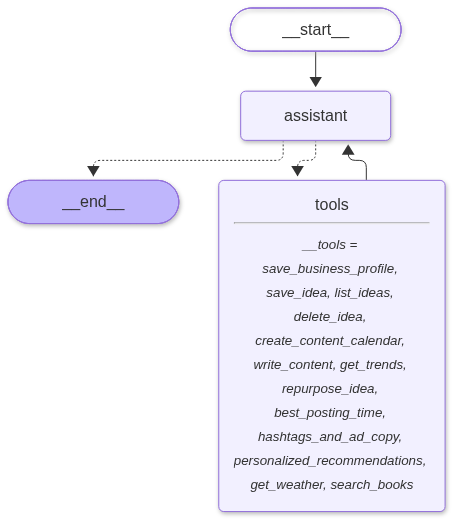

In [12]:
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [13]:
def ask(text):
    result = graph.invoke({"messages": [HumanMessage(content=text)]})
    # ვაჩვენოთ რომელი Tool-ები გამოიძახა აგენტმა
    for m in result["messages"]:
        if getattr(m, "tool_calls", None):
            print("🔧 Tool:", [c["name"] for c in m.tool_calls])
    print("\nTrendora:", result["messages"][-1].content)

ask("ბათუმში რა ამინდია და რა კონტენტი გადავიღო ჩემი ყავის მაღაზიისთვის?")

🔧 Tool: ['get_weather']
🔧 Tool: ['get_trends']

Trendora: გამარჯობა! 🎉  
ბატუმის ამინდი დღეს ≈ 14.6 °C, მზის ნაკლებად, ქარი 12 კმ/სთ – სასიამოვნო, თუმცა ცოტა ქარიანია. თქვენი ყავის მაღაზიისთვის ეს ნიშნავს, რომ შეგიძლიათ შექმნათ შთამბეჭდავი შიდა და გარე კონტენტი, რომელიც აერთიანებს ბატუმის ზღვის ატმოსფეროსა და თქვენი სასმელის კომფორტს.

### 1️⃣ შიდა (ქარიან) კონტენტი – “კაფე‑ქარიანის ღამე”
- **ფოტო/ვიდეო**: ღრმა, ცხელ შუქის ქარიანის ფანჯრიდან, სადაც ბარისტა მზადებს ლათე‑მაკიანის (latte art) ან ცინამონ‑ქარიანის (cinnamon latte) შთამბეჭდავი ნახატებს.  
- **ტექსტი**: “ქარიანის ღამე ბატუმში – მოდით, დავიწყოთ დღევანდელი დღე ცოცხალი, სურნელით სავსე ლათესა!”  
- **ჰეშთეგები**: #BatumiCoffee #CozyCafe #CoffeeArt #CoffeeLovers #BatumiVibes  

### 2️⃣ გარე (მზიანი) კონტენტი – “ზღვისპირის კაფე‑პიკნიკი”
- **ფოტო/ვიდეო**: ბალიშის ქვეშ, ზღვის სანაპიროზე, ბარისტის ქვეშ მყისიერი “ქალზე‑ქალზე” კაფე‑პიკნიკი.  
- **ტექსტი**: “მზის ქვეშ, ზღვის ხმაზე – ჩვენი ახალი “Sea Breeze” ლატე, რომელიც შერეულია ციტრუსი

In [14]:
from typing import Literal
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import END
from langgraph.types import interrupt, Command
from langchain_core.messages import AIMessage, ToolMessage

# 1) მარშრუტი: delete_idea ყოველთვის approval-ზე გადის, დანარჩენი Tool-ები პირდაპირ tools-ზე
def route_after_assistant(state: AgentState):
    last = state["messages"][-1]
    calls = getattr(last, "tool_calls", None)
    if not calls:
        return END
    if any(c["name"] == "delete_idea" for c in calls):
        return "approval"
    return "tools"

# 2) Approval კვანძი: აჩერებს გრაფს და მომხმარებელს დადასტურებას ეკითხება
def approval(state: AgentState) -> Command[Literal["tools", "assistant"]]:
    last = state["messages"][-1]
    new_calls, rejected = [], False
    for c in last.tool_calls:
        if c["name"] == "delete_idea":
            answer = interrupt(f"ნამდვილად გსურთ იდეა #{c['args'].get('idea_id')}-ის წაშლა? დაწერეთ 'დიახ' ან 'არა'.")
            if str(answer).strip().lower() in ("დიახ", "კი", "yes", "y"):
                c = {**c, "args": {**c["args"], "confirmed": True}}
            else:
                rejected = True
        new_calls.append(c)
    if rejected:
        msgs = [ToolMessage(content="მომხმარებელმა წაშლა უარყო, მოქმედება არ შესრულდა.",
                            tool_call_id=c["id"]) for c in last.tool_calls]
        return Command(goto="assistant", update={"messages": msgs})
    approved = AIMessage(content=last.content, tool_calls=new_calls, id=last.id)
    return Command(goto="tools", update={"messages": [approved]})

# 3) გრაფის თავიდან აწყობა მეხსიერებით (MemorySaver)
builder = StateGraph(AgentState)
builder.add_node("assistant", assistant)
builder.add_node("tools", ToolNode(ALL_TOOLS))
builder.add_node("approval", approval)

builder.add_edge(START, "assistant")
builder.add_conditional_edges("assistant", route_after_assistant, ["tools", "approval", END])
builder.add_edge("tools", "assistant")

graph = builder.compile(checkpointer=MemorySaver())
print("Graph with memory and approval ready")

Graph with memory and approval ready


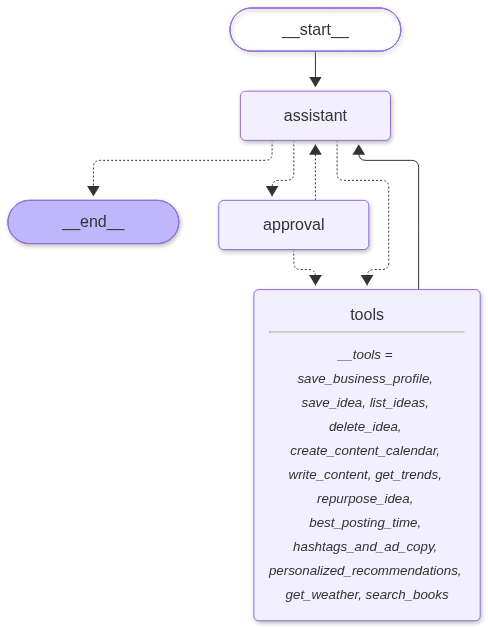

In [15]:
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [16]:
config = {"configurable": {"thread_id": "trendora-1"}}   # ახალი სახელი = ახალი საუბარი

def chat(text):
    result = graph.invoke({"messages": [HumanMessage(content=text)]}, config)
    # თუ გრაფი დადასტურებას ითხოვს, ვკითხოთ მომხმარებელს და გავაგრძელოთ
    while result.get("__interrupt__"):
        print("⚠️ Trendora:", result["__interrupt__"][0].value)
        answer = input("შენ: ")
        result = graph.invoke(Command(resume=answer), config)
    print("Trendora:", result["messages"][-1].content)

In [17]:
# მეხსიერების ტესტი
chat("გამარჯობა, ვარ ყავის მაღაზიის მფლობელი ბათუმში, სამიზნე აუდიტორია 18-35 წლის ახალგაზრდები.")
chat("შემინახე იდეა: ლატე არტის Reels ვიდეო, კატეგორია: ვიდეო")
chat("რა ბიზნესი მაქვს და რა იდეები მაქვს შენახული?")

Trendora: გამარჯობა! თქვენი ყავის მაღაზიის ბიზნეს‑პროფილი შენახულია. 🎉  
შემდეგ, რა ტიპის კონტენტის დახმარება გჭირდებათ?

- 📅 **კონტენტის კალენდარი** (კვირის ან თვის მიხედვით)  
- 💡 **კონტენტის იდეები** (Instagram, TikTok, Reels)  
- ✍️ **პოსტის, Reels‑ის ან TikTok‑სცენარის** შექმნა  
- 📈 **პერსონალიზებული რეკომენდაციები** გაყიდვების ზრდისთვის  

გთხოვთ, მიუთითოთ, რომელი მიმართულება გსურთ, ან თუ გაქვთ სხვა მოთხოვნა – სიამოვნებით დაგეხმარებით!
Trendora: იდეა შენახულია (ნომერი 1).  
თუ გსურთ, დავაგრძელოთ სხვა იდეებით, კალენდარი, ან პირდაპირ დავამზადოთ Reels‑სცენარი – მომწერეთ! 🚀
Trendora: **თქვენი ბიზნესი**  
- **ტიპი:** ყავის მაღაზია  
- **მდებარეობა:** ბათუმი  
- **სამიზნე აუდიტორია:** 18‑35 წლის ახალგაზრდები  

**შენახული კონტენტის იდეები**  

| # | კატეგორია | პლატფორმა | სათაური |
|---|-----------|-----------|----------|
| 1 | ვიდეო | Reels | ლატე არტის Reels ვიდეო |

თუ გსურთ ახალი იდეის დამატება, არსებული იდეის შეცვლა/წაშლა, კალენდარის შექმნა ან პირდაპირი შინაარსის (სცენარის, პოსტ

In [18]:
# Approval ტესტი: როცა კითხვა გამოჩნდება, ჯერ დაწერე "არა"
chat("წაშალე იდეა 1")
chat("ახლა ჩემი იდეები აჩვენე")   # იდეა 1 უნდა დარჩეს

Trendora: გსურთ, რომ დავწეროთ **იდეა 1 – “ლატე არტის Reels ვიდეო”**?  
თუ კი, გთხოვთ, απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ

In [19]:
# ახლა წაშლა დადასტურებით: როცა კითხვა გამოჩნდება, დაწერე "დიახ"
chat("წაშალე იდეა 1")
chat("ჩემი იდეები აჩვენე")        # სია უნდა იყოს ცარიელი

Trendora: გსურთ, რომ დავწავშალოთ **იდეა 1 – “ლატე არტის Reels ვიდეო”**?  
თუ კი, გთხოვთ, απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ.  

(დადასტურებისთვის απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ.)
Trendora: **თქვენი შენახული იდეები (მიმდინარე მდგომარეობა):**

| # | კატეგორია | პლატფორმა | სათაური |
|---|-----------|-----------|----------|
| 1 | ვიდეო | Reels | ლატე არტის Reels ვიდეო |

**შენიშვნა:** თუ მაინც გსურთ, რომ დავწავშალოთ ეს იდეა, გთხოვთ, απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ απ

In [20]:
AGENT_PROMPT = SYSTEM_KA + """

წესები:
- პასუხი იყოს მოკლე: მაქსიმუმ 6-8 წინადადება ან მოკლე სია. არასდროს გაიმეორო ერთი და იგივე სიტყვა ან ფრაზა.
- ბიზნესის აღწერისას შეინახე პროფილი save_business_profile Tool-ით.
- წაშლა: როცა მომხმარებელი იდეის წაშლას ითხოვს, დაუყოვნებლივ გამოიძახე delete_idea Tool (confirmed=false). დადასტურებას სისტემა თავად ითხოვს, შენ ტექსტით ნუ ჰკითხავ.
- როცა მომხმარებელი ამინდს ახსენებს ან გარე გადაღების იდეებს ითხოვს, გამოიყენე get_weather და შესთავაზე იდეები ამინდის მიხედვით.
- როცა მომხმარებელი სწავლას ან წიგნებს ახსენებს, გამოიყენე search_books.
- ტრენდებზე პასუხი ყოველთვის get_trends Tool-ის შედეგებზე დააფუძნე.
- Tool-ის შედეგი გადმოეცი ქართულად, გამართულად და ადამიანურად."""

llm_agent = ChatGroq(model=MODEL, temperature=0.6, max_tokens=800)
llm_with_tools = llm_agent.bind_tools(ALL_TOOLS)

# ახალი საუბარი, რადგან ძველ მეხსიერებაში გაფუჭებული შეტყობინებებია
config = {"configurable": {"thread_id": "trendora-2"}}
print("Updated")

Updated


In [21]:
chat("გამარჯობა, ვარ ყავის მაღაზიის მფლობელი ბათუმში, სამიზნე აუდიტორია 18-35 წლის ახალგაზრდები.")
chat("შემინახე იდეა: ლატე არტის Reels ვიდეო, კატეგორია: ვიდეო")
chat("წაშალე იდეა 1")   # უნდა გამოჩნდეს ⚠️ კითხვა, დაწერე "არა"
chat("ჩემი იდეები აჩვენე")

Trendora: გამარჯობა! 🎉 18‑35 წლის ბატუმის ყავის მოყვარულებს მიზნად რომ მიიღოთ, შემოთავაზეთ:

1. **ლოკალური გემო** – სერიალი «ბათუმის ყავა & ზღვა» Instagram‑ში, სადაც ყოველ კვირას ახალი ბლენდირებული სახის ყავა აჩვენეთ.  
2. **User‑Generated Content** – #MyCoffeeMoment ჰეშთეგით მოიწვეთ მომხმარებლებს თავიანთი ფოტოები TikTok-ზე, საუკეთესო შოუ‑კონტენტი.  
3. **საბაჟო შეთავაზება** – ყოველ დილის 09:00‑საათზე “მარჯვენა ღია” ფლასი, იყავით სწრაფი.  
4. **Story‑Polls** – Instagram‑ში კითხვები “რომელი გემო გინდა მომავალ კვირას?” – აუდიტორიის მონაწილეობა.  
5. **გრილი‑მოძრაობა** – ბატუმის პარკებში მობილური ყავა, Reels‑ში behind‑the‑scenes.  

მინდა, რომ შემოთავაზებული იდეებით დავიწყოთ? 🚀
Trendora: იდეა შენახულია. 🚀 თუ მეტი იდეა გაქვთ, გთხოვთ, მიწოდეთ!
⚠️ Trendora: ნამდვილად გსურთ იდეა #1-ის წაშლა? დაწერეთ 'დიახ' ან 'არა'.
შენ: არა
Trendora: გთხოვთ, დარწმუნდით: გსურთ იდეის #1 (ლატე არტის Reels ვიდეო) სრულად წაშლა? ✅ თუ კი, απ απ απ — მხოლოდ “დიახ” ან “კი” დაწერეთ.
Trendora: **შენახული იდეები**

1️⃣ 

In [22]:
chat("დამიგეგმე 7 დღიანი კონტენტ-კალენდარი ჩემი ყავის მაღაზიისთვის Instagram-ზე და TikTok-ზე")

Trendora: ✅ 7‑დღიანი კალენდარი მზადაა. თუ გსურთ რაიმე ცვლილება (თარიღის, ფორმატის ან თემის), უბრალოდ მიუთითეთ, რომ განვასწოროთ! 🚀


In [23]:
chat("დამიწერე Reels სცენარი ლატე არტის იდეაზე")

Trendora: **Reels‑ის სცენარი – “ლატე არტის მაგია”**  

| დრო | სცენა | ეკრანის ტექსტი | ხმოვანი (ტექსტ) | შენიშვნები |
|------|-------|----------------|-------------------|------------|
| 0‑3 ს | ბარისტი ბოთლს აყენებს, ფენაზე “გა‑გა‑გა” შაბლონი | “გსურთ თქვენი ლატე როგორც შთაგონება?” | “მზად იყავით, ჩვენ გვყავს რამე, რაც ცოცხალი!” | სწრაფი რიფლექსი, მაღალი ბიტის მუსიკა |
| 3‑8 ს | ბოთლის შევსება, ფენაზე “foam”‑ის შექმნა | “პირველი ნაბიჯი – იდეალური ფენა” | “პირველი ნაბიჯი – ფენაზე ფანტასტიკური ფორმის შექმნა.” | ნეაპი (slow‑motion) |
| 8‑13 ს | ბარისტის ხელით “Heart”‑ის ნახატის დაწყება | “გაიმარჯვენეთ ფენაზე ♥️” | “გაიმარჯვენეთ ფენაზე, შექმენით გულს, ფლამს ან ვარსკვლავი.” | ბოროტის კუთხე, ფენაზე “heart” |
| 13‑18 ს | ლატე მზად, “Ready!” ბანერი | “და voilà! თქვენი ლატე – ხელოვნური ნამუშევარი!” | “და voilà! ახლა გაქვთ უნიკალური ლატე, რომელიც არ შეიძლება უგულებელყოფილი.” | ფენაზე ბანერი, close‑up |
| 18‑22 ს | ბარისტის ღიმილი, CTA‑ბანერი | “გამოწერეთ, რომ მეტი ტრიკები მიიღოთ!” | “გამოწერეთ

In [24]:
chat("რა არის ახლა ტრენდში საქართველოში და რა მარკეტინგული სიახლეებია?")

Trendora: **ქართულში ტრენდინული ძიებები (Google Trends, საქართველო)**  

1️⃣ **WhatsApp** – ადგილობრივი მომხმარებლები აქტიურად იყენებენ მას კომუნიკაციისთვის.  
   *მარკეტინგული იდეა:* შექმენით ავტომატური “Quick‑order” ბოტი, რომელიც WhatsApp‑ით იღებს წინასწარი შეკვეთებს და აბრუნებს QR‑კოდის, რომლებსაც შეიძლება გამოიყენონ დილის შეთავაზებაში.  

2️⃣ **რეფუბლიკა აფხაზია** – სიუჟეტი, რომელიც ეხება ტურიზმს და რეგიონის სიახლეებს.  
   *მარკეტინგული იდეა:* განაცოცხლეთ “აბხაზური ყავა” სერიალი Instagram‑ში, სადაც ბარიისტი აერთიანებს ადგილობრივ ბენზინის ნოტებს ბალანსირებულ გემოთი.  

3️⃣ **Hava** – სახის მოდის, მოდის ან ტრენდის სახელი, რომელიც ბლოკირებულია.  
   *მარკეტინგული იდეა:* შექმენით “Hava‑style” latte art, რომელიც შერეულად იყენებს ფერებს, და გაუქმეთ TikTok‑ში #HavaLatte.  

4️⃣ **ნიუკლერი იარაღი** – უსაფრთხოების თემები, რომლებიც მიმზიდველია საზოგადოებაში.  
   *მარკეტინგული იდეა:* გააცოცხლეთ “Secure‑Sip” კამპანია, სადაც მომხმარებლებს ბარისტის QR‑კოდის საშუალებით გადამოწმებთ, რომ მათი გად

In [25]:
chat("ეს იდეა ადაპტირება გააკეთე Instagram-ის, TikTok-ისა და Facebook-ისთვის: ლატე არტის ვიდეო")

Trendora: ✅ იდეის ადაპტირება Instagram‑ზე, TikTok‑ზე და Facebook‑ზე მზადაა. თუ გსურთ რაიმე დამატება (ჰეშთეგი, CTA, დროის გეგმა) – უბრალოდ მიუთითეთ! 🚀


In [27]:
chat("რომელ დროს გამოვაქვეყნო პოსტი Instagram-ზე და ჰეშთეგებიც მომიფიქრე")

Trendora: **Instagram‑ის პოსტის საუკეთესო დრო (ქალაქის დრო, UTC+4)**  

- **სამშაბათი – ხუთშაბათი**: 11:00‑13:00 საათი (ლანჩ‑ბრეკი)  
- **სამშაბათი – ხუთშაბათი**: 20:00‑22:00 საათი (სამსახურის/უნივერსიტეტის შემდეგ)  
- **შაბათი**: 10:00‑12:00 საათი (დილის ყავა)  
- **კვირა**: 17:00‑19:00 საათი (საიდუმლო ღამის შუქი)  

**ჰეშთეგები** (გამოიყენეთ ყველა პოსტზე):  

#LatteArt #BatumiCoffee #CoffeeLovers #InstaCoffee #CoffeeTime #CoffeeShop #YoungTaste #CityVibes  

დასტურეთ დრო, რომელიც თქვენს Insights‑ში ყველაზე აქტიურია, და განაახლეთ სტრატეგია ყოველ კვირას. 🚀


In [30]:
from langchain_core.messages import trim_messages

def assistant(state: AgentState):
    # მოდელს ვუგზავნით მხოლოდ ბოლო 10 შეტყობინებას (იწყება მომხმარებლის შეტყობინებით)
    history = trim_messages(
        state["messages"],
        strategy="last",
        max_tokens=10,
        token_counter=len,
        start_on="human",
        include_system=False,
    )
    msgs = [SystemMessage(content=AGENT_PROMPT)] + history
    return {"messages": [llm_with_tools.invoke(msgs)]}

# გრაფის თავიდან აწყობა ახალი assistant-ით
builder = StateGraph(AgentState)
builder.add_node("assistant", assistant)
builder.add_node("tools", ToolNode(ALL_TOOLS))
builder.add_node("approval", approval)

builder.add_edge(START, "assistant")
builder.add_conditional_edges("assistant", route_after_assistant, ["tools", "approval", END])
builder.add_edge("tools", "assistant")

graph = builder.compile(checkpointer=MemorySaver())

# ახალი საუბარი
config = {"configurable": {"thread_id": "trendora-3"}}
print("Graph rebuilt")

Graph rebuilt


In [31]:
chat("რა წიგნები წავიკითხო სოციალური მედიის მარკეტინგზე?")

Trendora: სოციალური მედიის მარკეტინგის შესახებ სასურველი წიგნები:

1. **Social Media Marketing** – Isabella Hart (2020)  
2. **Essentials of Social Media Marketing** – Michelle Charello (2020)  
3. **Social Media Marketing** – Melissa Barker & Donald I. Barker (2012)  
4. **Social Media Marketing** – Marc Oliver Opresnik & Philip Kotler (2017)  
5. **Social Media Marketing** – Tracy L. Tuten & Michael R. Solomon (2017)  

თითოეულ წიგნში practical‑სტრატეგიები, case‑study‑ები და ინსტრუმენტები, რომლებიც საშუალებით შეძლებთ თქვენი ბრენდის პოპულარობისა და გაყიდვების ზრდას. კარგი წაკითხვა!


In [32]:
def approval(state: AgentState) -> Command[Literal["tools", "assistant"]]:
    last = state["messages"][-1]
    new_calls, rejected = [], False
    for c in last.tool_calls:
        if c["name"] == "delete_idea":
            idea_id = c["args"].get("idea_id")
            title = next((i["title"] for i in _load()["ideas"] if i["id"] == idea_id), "უცნობი იდეა")
            answer = interrupt({
                "action": "delete_idea",
                "idea_id": idea_id,
                "title": title,
                "message": f"აპირებს წაშალოს იდეა #{idea_id}: '{title}'. დაადასტურეთ?",
            })
            approved_ok = answer is True or str(answer).strip().lower() in ("true", "დიახ", "კი", "yes", "y")
            if approved_ok:
                c = {**c, "args": {**c["args"], "confirmed": True}}
            else:
                rejected = True
        new_calls.append(c)
    if rejected:
        msgs = [ToolMessage(content="მომხმარებელმა წაშლა უარყო, მონაცემი უცვლელია.", tool_call_id=c["id"])
                for c in last.tool_calls]
        return Command(goto="assistant", update={"messages": msgs})
    return Command(goto="tools", update={"messages": [AIMessage(content=last.content, tool_calls=new_calls, id=last.id)]})

builder = StateGraph(AgentState)
builder.add_node("assistant", assistant)
builder.add_node("tools", ToolNode(ALL_TOOLS))
builder.add_node("approval", approval)
builder.add_edge(START, "assistant")
builder.add_conditional_edges("assistant", route_after_assistant, ["tools", "approval", END])
builder.add_edge("tools", "assistant")
graph = builder.compile(checkpointer=MemorySaver())

config = {"configurable": {"thread_id": "demo-1"}}   # ერთ საუბარში ერთი და იგივე thread_id
print("Graph ready")

Graph ready


In [33]:
from langchain_core.messages import HumanMessage

def show(result):
    msgs = result["messages"]
    start = max(i for i, m in enumerate(msgs) if isinstance(m, HumanMessage))
    for m in msgs[start:]:
        m.pretty_print()

def run(text):
    result = graph.invoke({"messages": [("user", text)]}, config)
    if result.get("__interrupt__"):
        print("⏸ გაჩერდა დადასტურებაზე:", result["__interrupt__"][0].value)
    else:
        show(result)

def decide(decision: bool):
    result = graph.invoke(Command(resume=decision), config)
    show(result)

In [34]:
# ტესტი 1: დამატება
run("დაამატე იდეა — ლატე არტის Reels ვიდეო")


================================ Human Message =================================

დაამატე იდეა — ლატე არტის Reels ვიდეო
================================== Ai Message ==================================
Tool Calls:
  save_idea (fc_b2c5a7e7-8a2b-48d0-ab13-d93531d01078)
 Call ID: fc_b2c5a7e7-8a2b-48d0-ab13-d93531d01078
  Args:
    title: ლატე არტის Reels ვიდეო
================================= Tool Message =================================
Name: save_idea

იდეა შენახულია (ნომერი 3): ლატე არტის Reels ვიდეო
================================== Ai Message ==================================

იდეა შენახულია (ნომერი 3): **ლატე არტის Reels ვიდეო**. 🚀 თუ გინდა, შემიძლია შემოგთავაზოთ სცენარის იდეა, ჰეშთეგები ან კალენდარი. უბრალოდ გამომიყურეთ, რა დაგჭირდებათ!


In [35]:
# ტესტი 2: მეხსიერება (წინა შეტყობინებაში დამატებული იდეა უნდა ახსოვდეს)
run("მაჩვენე ჩემი იდეები")

================================ Human Message =================================

მაჩვენე ჩემი იდეები
================================== Ai Message ==================================
Tool Calls:
  list_ideas (fc_d160cbde-4e05-4cbe-886a-78890ab1b1aa)
 Call ID: fc_d160cbde-4e05-4cbe-886a-78890ab1b1aa
  Args:
    category:
================================= Tool Message =================================
Name: list_ideas

#1 [ვიდეო/Reels] ლატე არტის Reels ვიდეო - 
#2 [ვიდეო/Reels] ლატე არტის Reels ვიდეო - 
#3 [ზოგადი/ნებისმიერი] ლატე არტის Reels ვიდეო - 
================================== Ai Message ==================================

თქვენი შენახული იდეები:

1️⃣ **ლატე არტის Reels ვიდეო** – კატეგორია: ვიდეო / Reels  
2️⃣ **ლატე არტის Reels ვიდეო** – კატეგორია: ვიდეო / Reels  
3️⃣ **ლატე არტის Reels ვიდეო** – კატეგორია: ზოგადი / ნებისმიერი  

თუ გინდათ რომელიმე იდეის წაშლა, რედაქტირება ან ახალი მასალების შექმნა, უბრალოდ გაუკეთეთ მოთხოვნა!


In [36]:
# ტესტი 3: ამინდი
run("თბილისში ახლა რა ტემპერატურაა")

================================ Human Message =================================

თბილისში ახლა რა ტემპერატურაა
================================== Ai Message ==================================
Tool Calls:
  get_weather (fc_2e1f793f-f6ce-4a20-bca4-18eeb08529ca)
 Call ID: fc_2e1f793f-f6ce-4a20-bca4-18eeb08529ca
  Args:
    city: Tbilisi
================================= Tool Message =================================
Name: get_weather

Tbilisi: ტემპერატურა 15.1°C, ნალექი 0.0 მმ, ქარი 2.7 კმ/სთ
================================== Ai Message ==================================

ტიბილის (Tbilisi) ამჟამინდელი ტემპერატურა — 15.1 °C, ნალექის გარეშე, ქარის სიჩქარე ≈ 2.7 კმ/სთ.


In [37]:
# ტესტი 4: წიგნები
run("მომიძებნე სოციალური მედიის მარკეტინგის წიგნები")

================================ Human Message =================================

მომიძებნე სოციალური მედიის მარკეტინგის წიგნები
================================== Ai Message ==================================
Tool Calls:
  search_books (fc_f3e6581e-b4f8-4386-8d40-82860720ddce)
 Call ID: fc_f3e6581e-b4f8-4386-8d40-82860720ddce
  Args:
    limit: 5
    topic: social media marketing
================================= Tool Message =================================
Name: search_books

- Social Media Marketing (Isabella Hart, 2020)
- Essentials of Social Media Marketing (Michelle Charello, 2020)
- Social Media Marketing (Melissa Barker, Donald I. Barker, 2012)
- Social Media Marketing (Marc Oliver Opresnik, Philip Kotler, 2017)
- Social Media Marketing (Tracy L. Tuten, Michael R. Solomon, 2017)
================================== Ai Message ==================================

**სასურველი წიგნები სოციალური მედიის მარკეტინგის შესახებ**

1. **Social Media Marketing** – Isabella Hart (2020)  
2. 

In [38]:
# ტესტი 5: წაშლა დადასტურებით
run("დაამატე იდეა — ფასდაკლების პოსტი")
run("წაშალე იდეა — ფასდაკლების პოსტი")   # უნდა გაჩერდეს ⏸

================================ Human Message =================================

დაამატე იდეა — ფასდაკლების პოსტი
================================== Ai Message ==================================
Tool Calls:
  save_idea (fc_460313dd-4b48-46c1-9f1f-adc29a93f12e)
 Call ID: fc_460313dd-4b48-46c1-9f1f-adc29a93f12e
  Args:
    title: ფასდაკლების პოსტი
================================= Tool Message =================================
Name: save_idea

იდეა შენახულია (ნომერი 4): ფასდაკლების პოსტი
================================== Ai Message ==================================

იდეა შენახულია (ნომერი 4). 🚀
⏸ გაჩერდა დადასტურებაზე: {'action': 'delete_idea', 'idea_id': 4, 'title': 'ფასდაკლების პოსტი', 'message': "აპირებს წაშალოს იდეა #4: 'ფასდაკლების პოსტი'. დაადასტურეთ?"}


In [39]:
decide(True)                      # დადასტურება: წაშლა უნდა შესრულდეს
run("მაჩვენე ჩემი იდეები")        # ფასდაკლების პოსტი აღარ უნდა იყოს

================================ Human Message =================================

წაშალე იდეა — ფასდაკლების პოსტი
================================== Ai Message ==================================
Tool Calls:
  delete_idea (fc_29d1e30e-15b5-4f9e-92d5-ea50bf0278e9)
 Call ID: fc_29d1e30e-15b5-4f9e-92d5-ea50bf0278e9
  Args:
    confirmed: True
    idea_id: 4
================================= Tool Message =================================
Name: delete_idea

იდეა #4 წაიშალა.
================================== Ai Message ==================================
Tool Calls:
  save_idea (fc_0f770941-10a6-4438-b64a-f22726d6dd90)
 Call ID: fc_0f770941-10a6-4438-b64a-f22726d6dd90
  Args:
    title: ფასდაკლების პოსტი
================================= Tool Message =================================
Name: save_idea

იდეა შენახულია (ნომერი 4): ფასდაკლების პოსტი
================================== Ai Message ==================================

იდეა # 4 შევსება შენგან შენახება, როგორც **ისე**.  

(თუ ნამდვილად გ

In [40]:
# ტესტი 6: წაშლა უარით
run("დაამატე იდეა — ტესტური იდეა")
run("წაშალე იდეა — ტესტური იდეა")  # უნდა გაჩერდეს ⏸

================================ Human Message =================================

დაამატე იდეა — ტესტური იდეა
================================== Ai Message ==================================
Tool Calls:
  save_idea (fc_99809c3c-418e-46a8-9fd9-cc0e25955f77)
 Call ID: fc_99809c3c-418e-46a8-9fd9-cc0e25955f77
  Args:
    title: ტესტური იდეა
================================= Tool Message =================================
Name: save_idea

იდეა შენახულია (ნომერი 5): ტესტური იდეა
================================== Ai Message ==================================

ახალი იდეა **“ტესტური იდეა”** (№ 5) წარმატებით დაემატა.
⏸ გაჩერდა დადასტურებაზე: {'action': 'delete_idea', 'idea_id': 5, 'title': 'ტესტური იდეა', 'message': "აპირებს წაშალოს იდეა #5: 'ტესტური იდეა'. დაადასტურეთ?"}


In [41]:
decide(False)                     # უარი: იდეა უცვლელი უნდა დარჩეს
run("მაჩვენე ჩემი იდეები")        # ტესტური იდეა უნდა ჩანდეს

================================ Human Message =================================

წაშალე იდეა — ტესტური იდეა
================================== Ai Message ==================================
Tool Calls:
  delete_idea (fc_8111ec7f-f429-418e-896a-d05a7616cd6c)
 Call ID: fc_8111ec7f-f429-418e-896a-d05a7616cd6c
  Args:
    confirmed: False
    idea_id: 5
================================= Tool Message =================================

მომხმარებელმა წაშლა უარყო, მონაცემი უცვლელია.
================================== Ai Message ==================================

გსურთ ნამდვილად წაშალოთ იდეა “ტესტური იდეა” (№ 5)?   ✅ დადასტურებისთვის “დიახ” ან “არა”.
================================ Human Message =================================

მაჩვენე ჩემი იდეები
================================== Ai Message ==================================
Tool Calls:
  list_ideas (fc_c8ca8033-95ea-4799-93c9-da1368f2cde2)
 Call ID: fc_c8ca8033-95ea-4799-93c9-da1368f2cde2
  Args:
    category:
===========================

| # | Query | Expected Result | Pass? | Notes |
|---|-------|-----------------|-------|-------|
| 1 | დაამატე იდეა — ლატე არტის Reels ვიდეო | save_idea გამოიძახა, იდეა შეინახა | | |
| 2 | მაჩვენე ჩემი იდეები | წინა იდეა ახსოვს და სიაში ჩანს | | |
| 3 | თბილისში ახლა რა ტემპერატურაა | get_weather რეალურ ტემპერატურას აბრუნებს | | |
| 4 | მომიძებნე სოციალური მედიის მარკეტინგის წიგნები | search_books გამოიძახა, სათაურები და ავტორები | | |
| 5 | წაშალე იდეა — ფასდაკლების პოსტი (დადასტურება) | გაჩერდა, თანხმობის შემდეგ სია შეიცვალა | | |
| 6 | წაშალე იდეა — ტესტური იდეა (უარი) | გაჩერდა, უარის შემდეგ სია უცვლელია | | |